<a href="https://colab.research.google.com/github/IAMIOT1/h-c-m-y-/blob/main/De_tai_9_Phan_loai_nam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Nhập thư viện và tải dữ liệu

In [1]:
import io
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Kích thước:", df.shape)
display(df.head(10))

Saving mushrooms.csv to mushrooms.csv
Kích thước: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
5,e,x,y,y,t,a,f,c,b,n,...,s,w,w,p,w,o,p,k,n,g
6,e,b,s,w,t,a,f,c,b,g,...,s,w,w,p,w,o,p,k,n,m
7,e,b,y,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,s,m
8,p,x,y,w,t,p,f,c,n,p,...,s,w,w,p,w,o,p,k,v,g
9,e,b,s,y,t,a,f,c,b,g,...,s,w,w,p,w,o,p,k,s,m


2. EDA: kiểm tra cấu trúc, thiếu nhãn và dữ liệu

THÔNG TIN DỮ LIỆU
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728



Số dòng trùng: 0


,Số mẫu,Tỷ lệ (%)
class,,
Ăn được,4208,51.8
Độc,3916,48.2


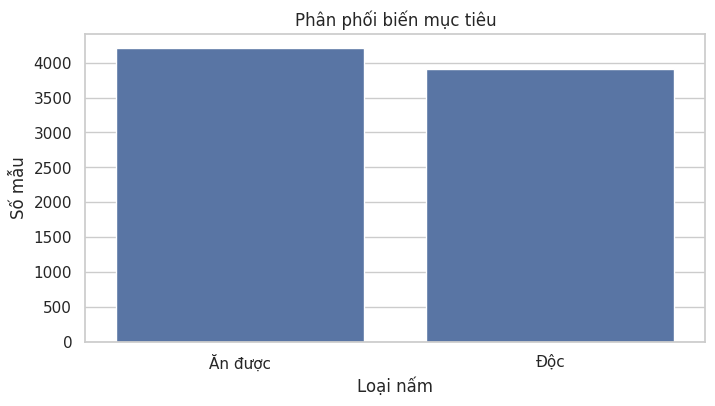

,Số lượng thiếu,Tỷ lệ thiếu (%)
stalk-root,2480,30.53


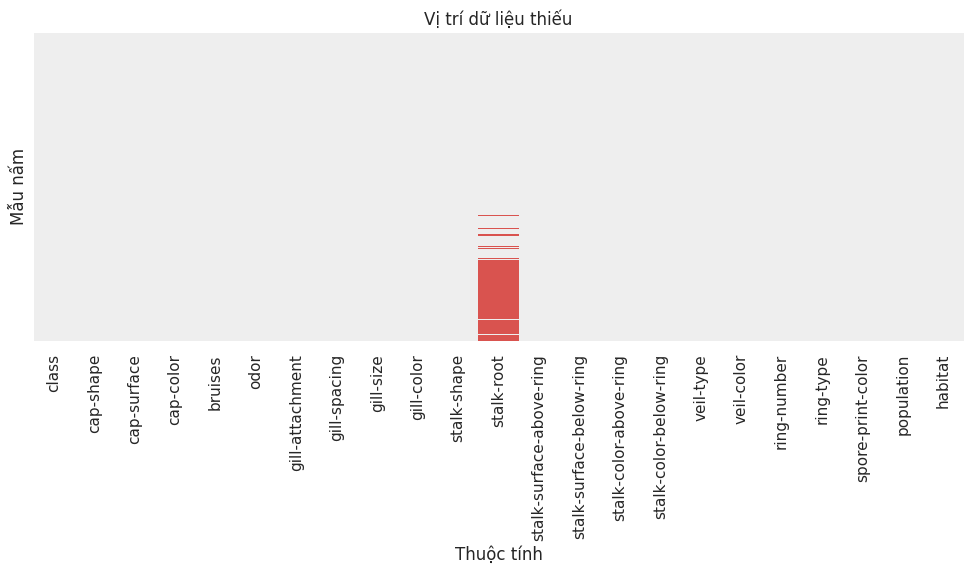

In [2]:
print("THÔNG TIN DỮ LIỆU")
df.info()

print("\nThống kê các thuộc tính phân loại:")
display(df.describe(include="all").T)

print("\nSố dòng trùng:", df.duplicated().sum())

# Đổi ? thành giá trị thiếu thực sự
data = df.replace("?", np.nan).drop_duplicates().copy()

nhan = data["class"].map({
    "e": "Ăn được",
    "p": "Độc"
})

bang_nhan = nhan.value_counts().to_frame("Số mẫu")
bang_nhan["Tỷ lệ (%)"] = (
    bang_nhan["Số mẫu"] / len(data) * 100
)
display(bang_nhan.round(2))

sns.countplot(x=nhan, order=["Ăn được", "Độc"])
plt.title("Phân phối biến mục tiêu")
plt.xlabel("Loại nấm")
plt.ylabel("Số mẫu")
plt.show()

thieu = pd.DataFrame({
    "Số lượng thiếu": data.isna().sum(),
    "Tỷ lệ thiếu (%)": data.isna().mean() * 100
})

display(
    thieu[thieu["Số lượng thiếu"] > 0].round(2)
)

plt.figure(figsize=(12, 4))
sns.heatmap(
    data.isna(),
    cbar=False,
    yticklabels=False,
    cmap=["#eeeeee", "#d9534f"]
)
plt.title("Vị trí dữ liệu thiếu")
plt.xlabel("Thuộc tính")
plt.ylabel("Mẫu nấm")
plt.show()

3. EDA: phân tích từng đặc trưng và quan hệ với nhãn

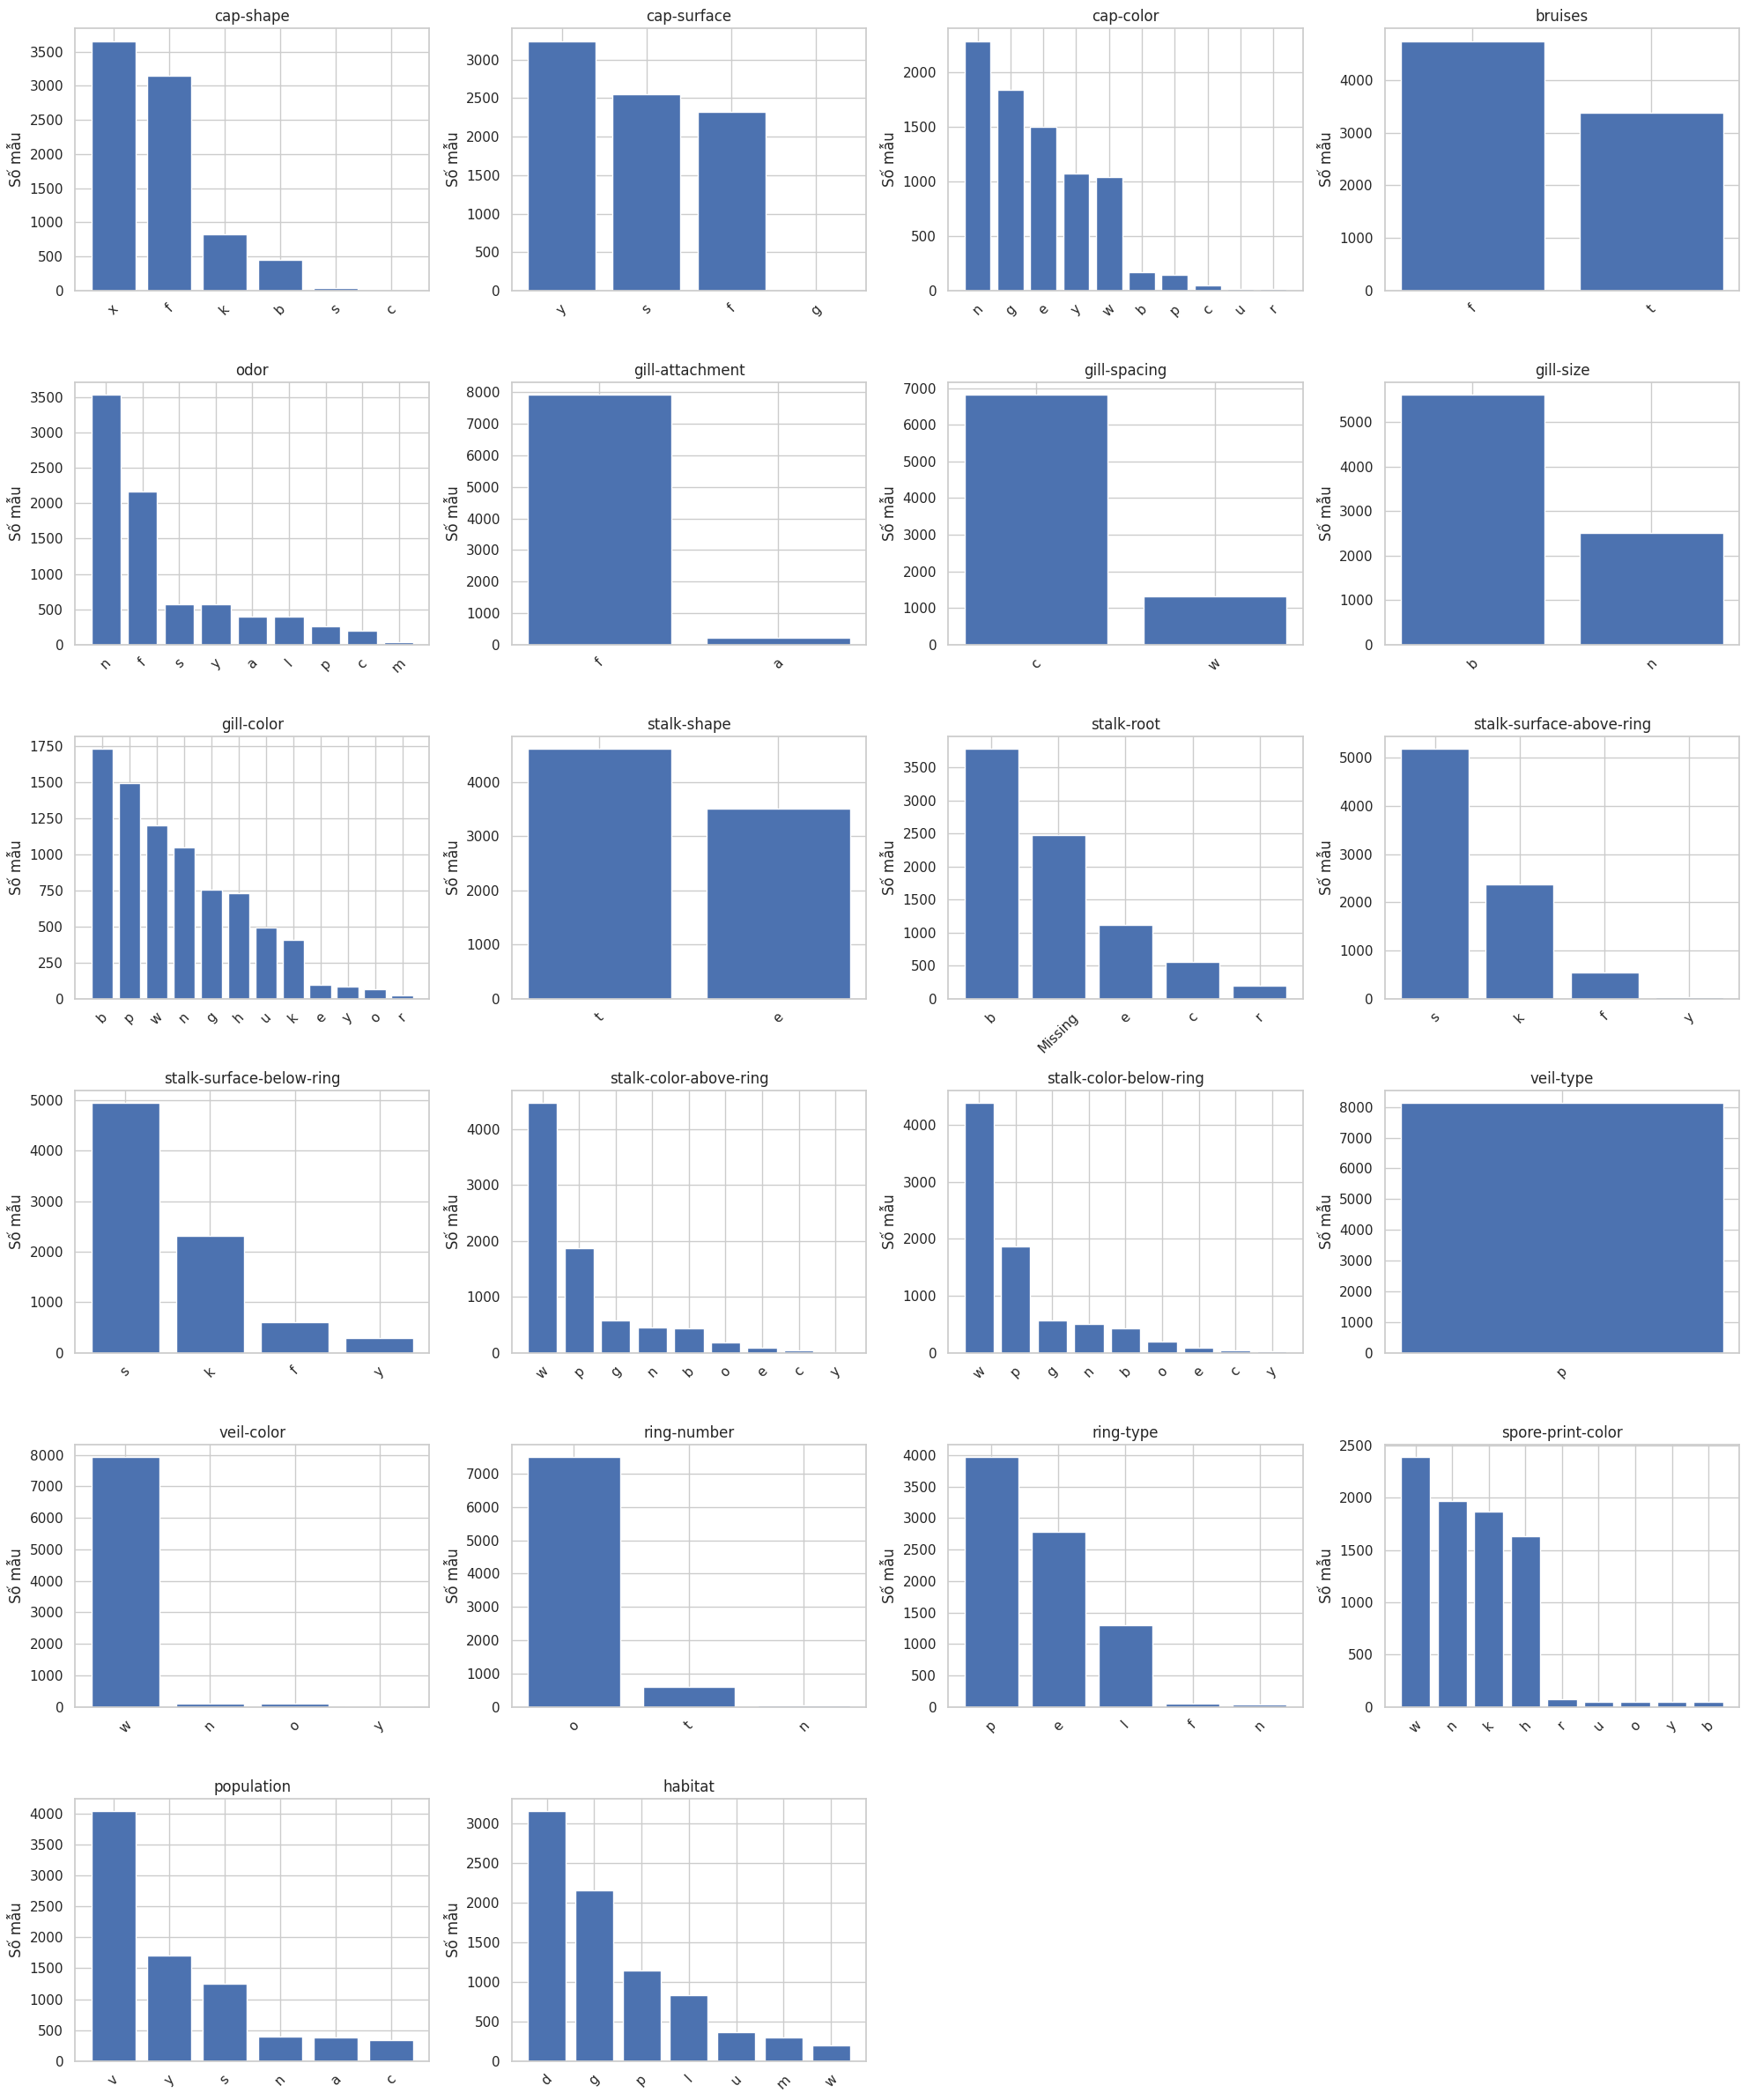

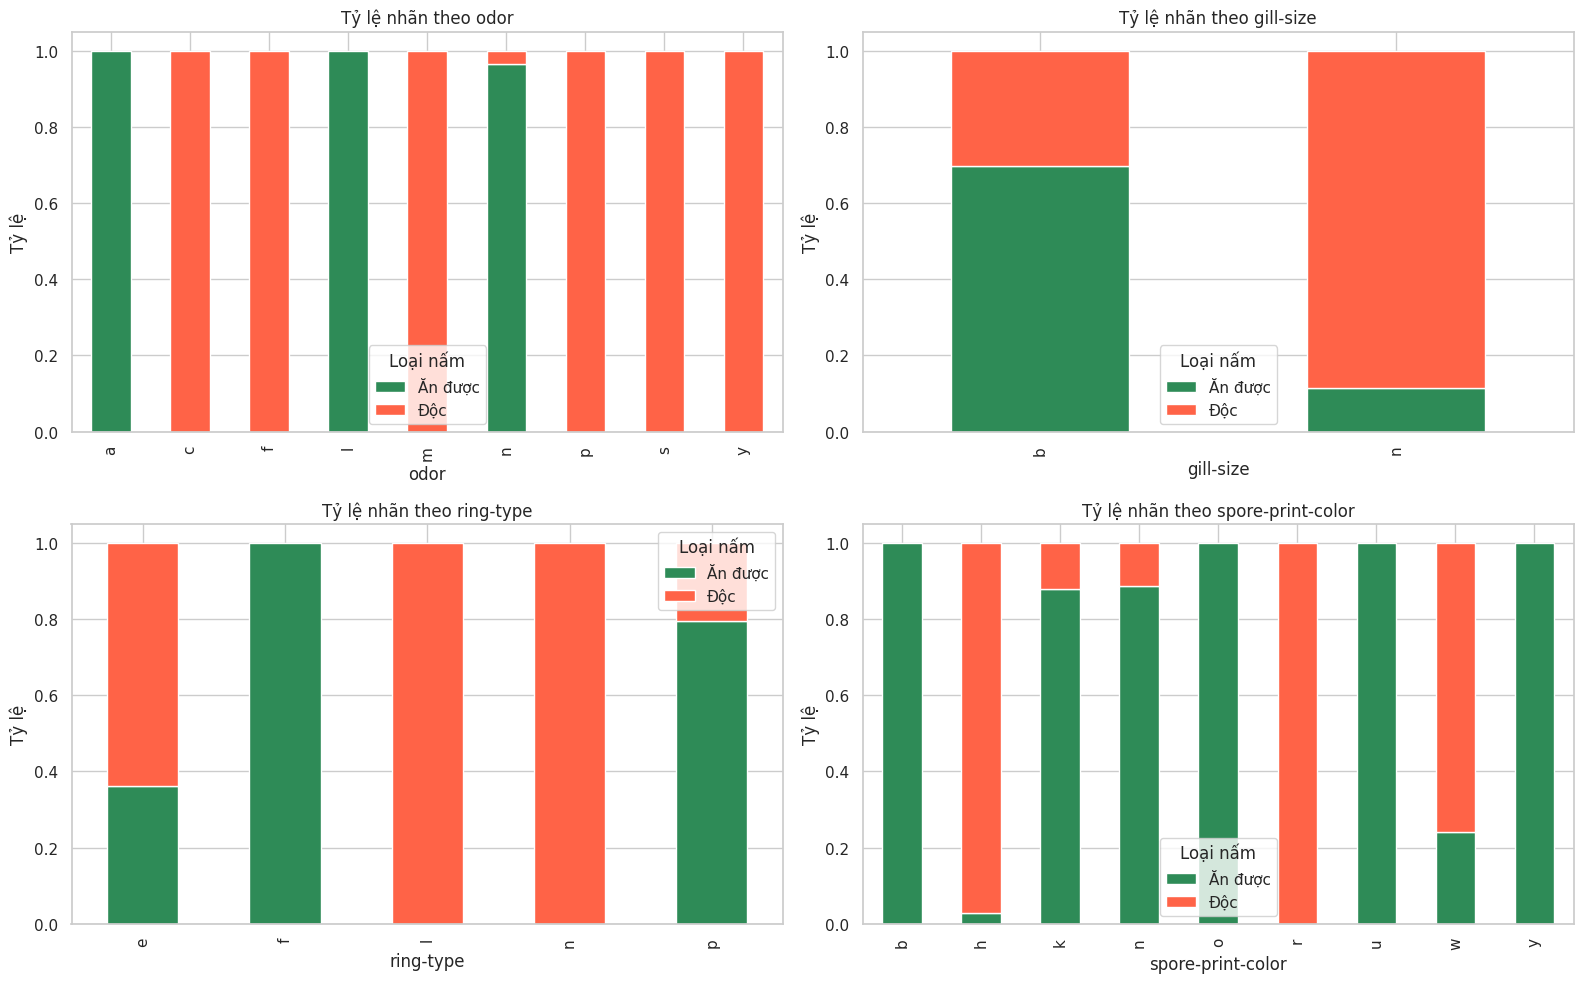

In [3]:
feature_cols = data.columns.drop("class")

# Tần suất từng giá trị của toàn bộ đặc trưng
fig, axes = plt.subplots(6, 4, figsize=(20, 24))
axes = axes.ravel()

for ax, cot in zip(axes, feature_cols):
    tan_suat = (
        data[cot]
        .fillna("Missing")
        .value_counts()
    )

    ax.bar(tan_suat.index.astype(str), tan_suat.values)
    ax.set_title(cot)
    ax.set_ylabel("Số mẫu")
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(feature_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Quan hệ giữa một số đặc trưng và nhãn
cac_cot = [
    "odor",
    "gill-size",
    "ring-type",
    "spore-print-color"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, cot in zip(axes.ravel(), cac_cot):
    bang = pd.crosstab(
        data[cot].fillna("Missing"),
        nhan,
        normalize="index"
    )

    bang = bang.reindex(
        columns=["Ăn được", "Độc"],
        fill_value=0
    )

    bang.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=["seagreen", "tomato"]
    )

    ax.set_title(f"Tỷ lệ nhãn theo {cot}")
    ax.set_ylabel("Tỷ lệ")
    ax.legend(title="Loại nấm")

plt.tight_layout()
plt.show()

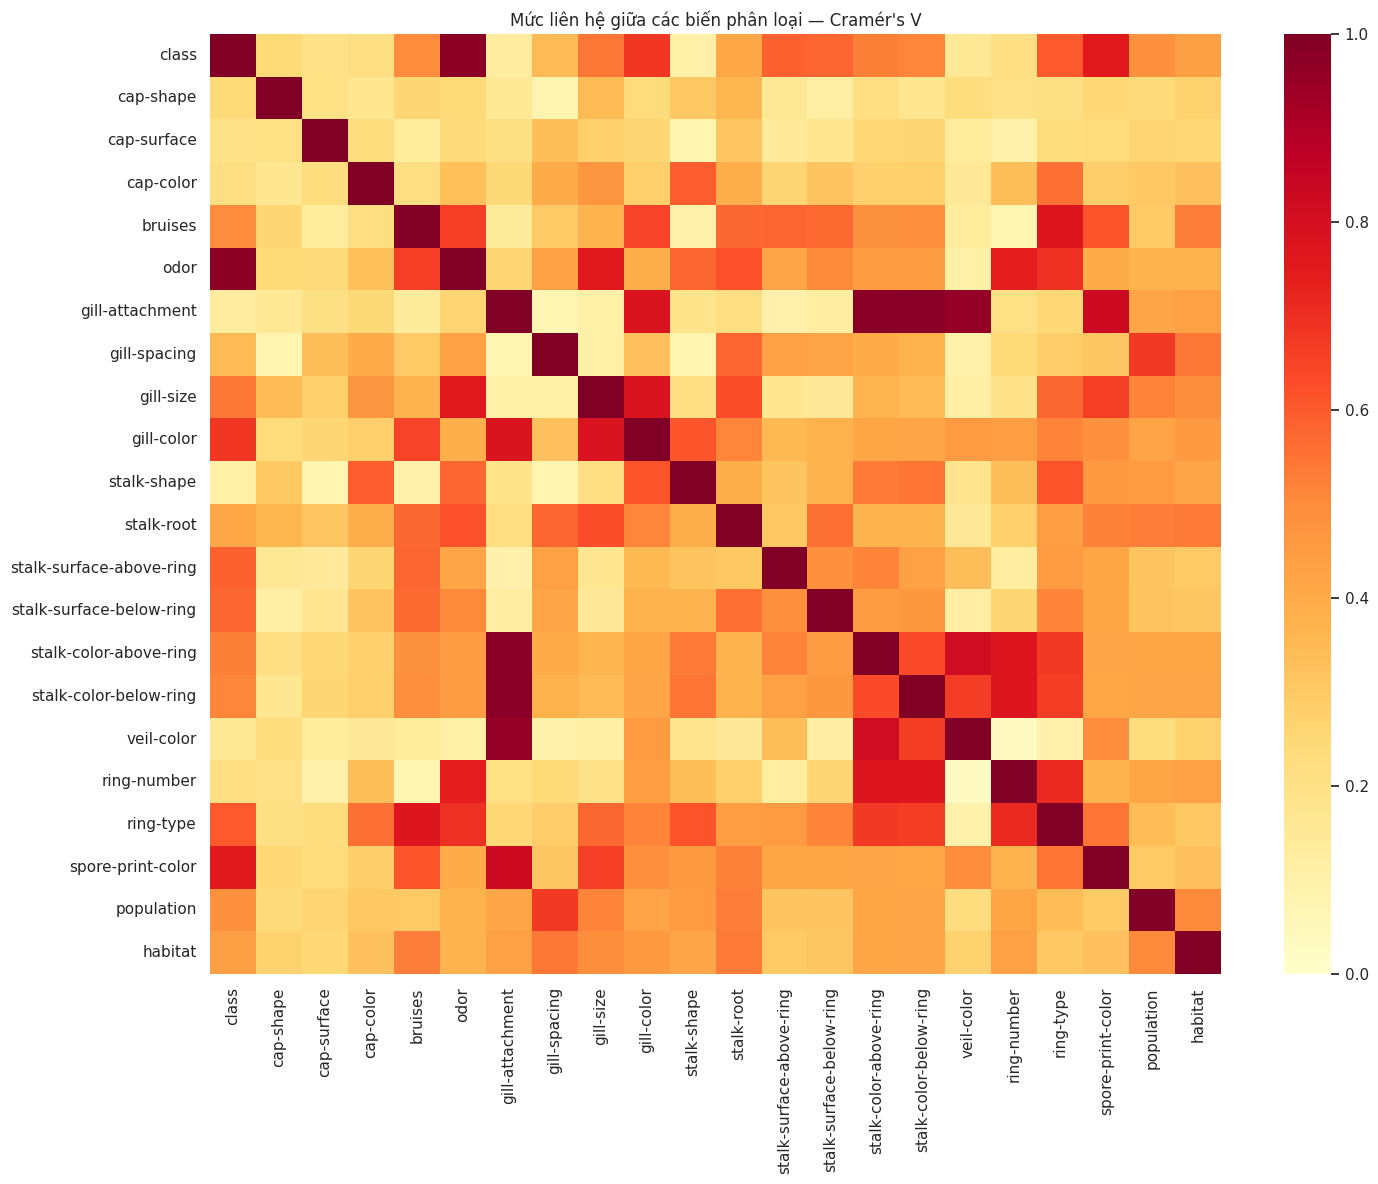

,Liên hệ với nhãn
odor,0.971005
spore-print-color,0.752645
gill-color,0.680830
ring-type,0.603271
stalk-surface-above-ring,0.587944
stalk-surface-below-ring,0.574837
gill-size,0.540024
stalk-color-above-ring,0.524850
stalk-color-below-ring,0.514725
bruises,0.501530


In [4]:
from scipy.stats.contingency import association

def cramers_v(a, b):
    table = pd.crosstab(
        a.fillna("Missing"),
        b.fillna("Missing")
    )

    if min(table.shape) < 2:
        return np.nan

    return association(
        table.to_numpy(),
        method="cramer",
        correction=False
    )

# Bỏ biến hằng vì không tính được mức liên hệ có ý nghĩa
cot_lien_he = [
    cot for cot in data.columns
    if data[cot].nunique(dropna=False) > 1
]

matrix = pd.DataFrame(
    index=cot_lien_he,
    columns=cot_lien_he,
    dtype=float
)

for cot_1 in cot_lien_he:
    for cot_2 in cot_lien_he:
        matrix.loc[cot_1, cot_2] = cramers_v(
            data[cot_1], data[cot_2]
        )

plt.figure(figsize=(15, 12))
sns.heatmap(matrix, cmap="YlOrRd", vmin=0, vmax=1)
plt.title("Mức liên hệ giữa các biến phân loại — Cramér's V")
plt.tight_layout()
plt.show()

display(
    matrix["class"]
    .drop("class")
    .sort_values(ascending=False)
    .to_frame("Liên hệ với nhãn")
)

4. Chia đào tạo, xác nhận và kiểm tra

In [5]:
X = data.drop(columns="class")
y = data["class"].map({"e": 0, "p": 1})

assert y.notna().all(), "Có nhãn không hợp lệ!"

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.25,
    stratify=y_trainval,
    random_state=SEED
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (4874, 22)
Validation: (1625, 22)
Test: (1625, 22)


5. Luồng A: xử lý thiếu và One-Hot Encoding

In [6]:
# Chỉ xác định biến hằng từ tập train
cot_giu = X_train.columns[
    X_train.nunique(dropna=False) > 1
].tolist()

X_train = X_train[cot_giu]
X_val = X_val[cot_giu]
X_test = X_test[cot_giu]

# Học giá trị thay thế từ train
imputer = SimpleImputer(strategy="most_frequent")

train_filled = imputer.fit_transform(X_train)
val_filled = imputer.transform(X_val)
test_filled = imputer.transform(X_test)

# Học danh sách giá trị phân loại từ train
ohe = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=np.float32
)

A_train = ohe.fit_transform(train_filled)
A_val = ohe.transform(val_filled)
A_test = ohe.transform(test_filled)

print("Số đặc trưng gốc được giữ:", len(cot_giu))
print("Số đặc trưng sau One-Hot:", A_train.shape[1])

display(
    pd.DataFrame(
        A_train[:5],
        columns=ohe.get_feature_names_out(cot_giu)
    )
)

Số đặc trưng gốc được giữ: 21
Số đặc trưng sau One-Hot: 115


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


6. Luồng B: xây dựng Autoencode

In [7]:
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

def tao_autoencoder(input_dim, latent_dim):
    inputs = Input(shape=(input_dim,), name="input")

    x = Dense(64, activation="relu")(inputs)
    x = Dense(32, activation="relu")(x)

    latent = Dense(
        latent_dim,
        activation="linear",
        name="bottleneck"
    )(x)

    x = Dense(32, activation="relu")(latent)
    x = Dense(64, activation="relu")(x)

    outputs = Dense(
        input_dim,
        activation="sigmoid"
    )(x)

    autoencoder = Model(inputs, outputs)
    encoder = Model(inputs, latent)

    autoencoder.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return autoencoder, encoder

ae_candidates = {}
ae_rows = []

for z in [8, 16, 32]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    ae, encoder = tao_autoencoder(
        A_train.shape[1], z
    )

    start = time.perf_counter()

    history = ae.fit(
        A_train,
        A_train,
        validation_data=(A_val, A_val),
        epochs=100,
        batch_size=128,
        shuffle=True,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=10,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    training_seconds = time.perf_counter() - start
    val_mse = ae.evaluate(A_val, A_val, verbose=0)

    ae_candidates[z] = {
        "autoencoder": ae,
        "encoder": encoder,
        "history": history.history
    }

    ae_rows.append({
        "Số chiều ẩn": z,
        "Validation MSE": val_mse,
        "Số epochs đã chạy": len(history.history["loss"]),
        "Thời gian AE (giây)": training_seconds
    })

ae_table = pd.DataFrame(ae_rows).sort_values(
    "Validation MSE"
)

display(ae_table)

,Số chiều ẩn,Validation MSE,Số epochs đã chạy,Thời gian AE (giây)
2,32,0.006414,100,26.995222
1,16,0.009391,100,28.560016
0,8,0.017303,100,29.566364


7. Chọn Encoder và trích xuất đặc trưng

Kích thước lớp ẩn được chọn: 32


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 115)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         7,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 115)            │         7,475 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,611 (248.48 KB)

 Trainable params: 21,203 (82.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 42,408 (165.66 KB)

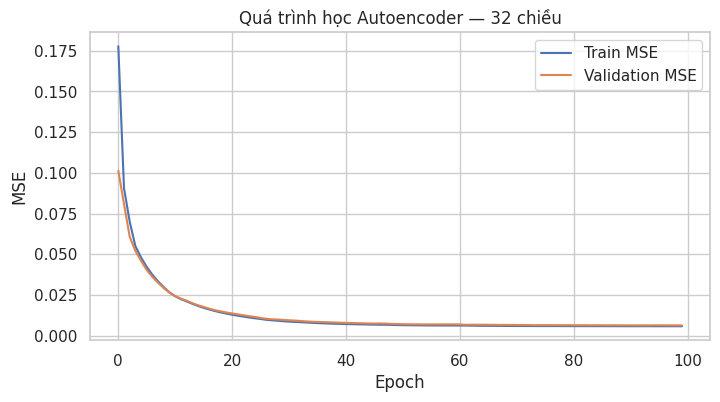

Luồng A: (4874, 115)
Luồng B: (4874, 32)
Tỷ lệ giảm số chiều: 72.17%


,z_1,z_2,z_3,z_4,z_5,z_6,z_7,z_8,z_9,z_10,...,z_23,z_24,z_25,z_26,z_27,z_28,z_29,z_30,z_31,z_32
0,13.568815,-25.478899,23.056501,-8.262081,-11.699877,-30.491749,-12.038990,5.754870,17.655579,-1.622074,...,12.644168,-11.223839,-5.104093,-9.698991,7.526758,-12.622663,-0.837623,26.648975,-12.546068,-38.439877
1,20.263115,-19.983559,22.581848,-14.877818,6.093578,-22.893602,6.369523,5.793780,7.832275,-2.255017,...,23.231123,-22.293648,-2.607194,-25.339714,1.005952,-5.874886,-18.022905,29.084644,-4.675259,-15.774480
2,25.967997,-18.485609,14.183174,-12.732601,5.091846,-26.393000,4.053109,7.636255,8.135144,-12.268863,...,25.144852,-24.061607,-0.995117,-15.609391,-8.209277,0.042733,-20.449726,31.307659,-6.657121,-25.160236
3,10.961734,-13.080381,20.964443,-29.768675,-2.244326,-24.924143,-10.148858,-12.232090,-3.608616,0.281465,...,2.337979,-15.969274,-4.055183,-6.653444,-1.547134,-15.100744,0.486733,27.509701,-5.601697,-32.137218
4,15.139028,-7.086273,18.026802,-38.917023,3.099270,-15.337595,-4.286786,-17.448479,-4.788022,7.587049,...,1.264550,-15.922642,-6.243224,-15.882908,-3.282307,-12.338419,-4.233554,28.834284,-7.170682,-26.642313


In [8]:
best_z = int(ae_table.iloc[0]["Số chiều ẩn"])

best_ae = ae_candidates[best_z]["autoencoder"]
best_encoder = ae_candidates[best_z]["encoder"]
history = ae_candidates[best_z]["history"]

print("Kích thước lớp ẩn được chọn:", best_z)
best_ae.summary()

plt.plot(history["loss"], label="Train MSE")
plt.plot(history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(f"Quá trình học Autoencoder — {best_z} chiều")
plt.legend()
plt.show()

B_train = best_encoder.predict(A_train, verbose=0)
B_val = best_encoder.predict(A_val, verbose=0)
B_test = best_encoder.predict(A_test, verbose=0)

print("Luồng A:", A_train.shape)
print("Luồng B:", B_train.shape)

print(
    "Tỷ lệ giảm số chiều:",
    f"{(1 - best_z / A_train.shape[1]) * 100:.2f}%"
)

display(
    pd.DataFrame(
        B_train[:5],
        columns=[f"z_{i+1}" for i in range(best_z)]
    )
)

8. Select tham số cho KNN và Naive Bayes

In [9]:
feature_sets = {
    "A": (A_train, A_val, A_test),
    "B": (B_train, B_val, B_test)
}

selected_models = {}
validation_rows = []

for luong, (train_x, val_x, _) in feature_sets.items():

    for algorithm in ["KNN", "GaussianNB"]:
        candidates = []

        if algorithm == "KNN":
            for k in [3, 5, 7, 9, 11, 15]:
                for p in [1, 2]:
                    classifier = KNeighborsClassifier(
                        n_neighbors=k,
                        metric="minkowski",
                        p=p,
                        n_jobs=-1
                    )

                    model = (
                        make_pipeline(
                            StandardScaler(),
                            classifier
                        )
                        if luong == "B"
                        else classifier
                    )

                    candidates.append((
                        f"k={k}, p={p}",
                        model
                    ))

        else:
            for smoothing in [1e-11, 1e-9, 1e-7, 1e-5]:
                candidates.append((
                    f"var_smoothing={smoothing}",
                    GaussianNB(var_smoothing=smoothing)
                ))

        best_key = None
        best_record = None

        for params, model in candidates:
            start = time.perf_counter()
            model.fit(train_x, y_train)
            fit_seconds = time.perf_counter() - start

            pred = model.predict(val_x)

            f1 = f1_score(y_val, pred, zero_division=0)
            recall = recall_score(y_val, pred, zero_division=0)
            accuracy = accuracy_score(y_val, pred)

            # Ưu tiên F1, sau đó Recall và Accuracy
            key = (f1, recall, accuracy)

            validation_rows.append({
                "Luồng": luong,
                "Thuật toán": algorithm,
                "Tham số": params,
                "Validation F1": f1,
                "Validation Recall": recall,
                "Validation Accuracy": accuracy
            })

            if best_key is None or key > best_key:
                best_key = key
                best_record = {
                    "model": model,
                    "params": params,
                    "fit_seconds": fit_seconds
                }

        selected_models[(luong, algorithm)] = best_record

validation_table = pd.DataFrame(validation_rows)

display(
    validation_table.sort_values(
        ["Luồng", "Thuật toán", "Validation F1"],
        ascending=[True, True, False]
    ).round(4)
)

,Luồng,Thuật toán,Tham số,Validation F1,Validation Recall,Validation Accuracy
15,A,GaussianNB,var_smoothing=1e-05,0.9886,1.0000,0.9889
14,A,GaussianNB,var_smoothing=1e-07,0.9769,1.0000,0.9772
13,A,GaussianNB,var_smoothing=1e-09,0.9526,1.0000,0.9520
12,A,GaussianNB,var_smoothing=1e-11,0.9372,1.0000,0.9354
0,A,KNN,"k=3, p=1",1.0000,1.0000,1.0000
1,A,KNN,"k=3, p=2",1.0000,1.0000,1.0000
2,A,KNN,"k=5, p=1",1.0000,1.0000,1.0000
3,A,KNN,"k=5, p=2",1.0000,1.0000,1.0000
4,A,KNN,"k=7, p=1",1.0000,1.0000,1.0000
5,A,KNN,"k=7, p=2",1.0000,1.0000,1.0000


9.Đánh giá cấu hình trên cùng một tập tin

In [10]:
test_rows = []
test_predictions = {}
test_probabilities = {}

for (luong, algorithm), record in selected_models.items():
    model = record["model"]
    test_x = feature_sets[luong][2]

    start = time.perf_counter()

    pred = model.predict(test_x)
    proba = model.predict_proba(test_x)[
        :, list(model.classes_).index(1)
    ]

    predict_seconds = time.perf_counter() - start

    name = f"{luong} - {algorithm}"

    test_predictions[name] = pred
    test_probabilities[name] = proba

    test_rows.append({
        "Luồng": luong,
        "Thuật toán": algorithm,
        "Số chiều": test_x.shape[1],
        "Tham số": record["params"],
        "Accuracy": accuracy_score(y_test, pred),
        "Precision độc": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall độc": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1 độc": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Nấm độc bị bỏ sót": int(
            ((y_test.to_numpy() == 1) & (pred == 0)).sum()
        ),
        "Fit bộ phân loại (giây)": record["fit_seconds"],
        "Dự đoán + xác suất (giây)": predict_seconds
    })

    print("\n" + name)
    print(classification_report(
        y_test,
        pred,
        labels=[0, 1],
        target_names=["Ăn được", "Độc"],
        digits=4,
        zero_division=0
    ))

results = pd.DataFrame(test_rows)
display(results.round(4))


A - KNN
              precision    recall  f1-score   support

     Ăn được     1.0000    1.0000    1.0000       842
         Độc     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625


A - GaussianNB
              precision    recall  f1-score   support

     Ăn được     0.9976    0.9857    0.9916       842
         Độc     0.9849    0.9974    0.9911       783

    accuracy                         0.9914      1625
   macro avg     0.9912    0.9916    0.9914      1625
weighted avg     0.9915    0.9914    0.9914      1625


B - KNN
              precision    recall  f1-score   support

     Ăn được     1.0000    1.0000    1.0000       842
         Độc     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0

,Luồng,Thuật toán,Số chiều,Tham số,Accuracy,Precision độc,Recall độc,F1 độc,ROC-AUC,Nấm độc bị bỏ sót,Fit bộ phân loại (giây),Dự đoán + xác suất (giây)
0,A,KNN,115,"k=3, p=1",1.0000,1.0000,1.0000,1.0000,1.0000,0,0.0023,2.8702
1,A,GaussianNB,115,var_smoothing=1e-05,0.9914,0.9849,0.9974,0.9911,0.9993,2,0.0048,0.0054
2,B,KNN,32,"k=3, p=1",1.0000,1.0000,1.0000,1.0000,1.0000,0,0.0062,0.7481
3,B,GaussianNB,32,var_smoothing=1e-11,0.9157,0.9792,0.8429,0.9060,0.9595,123,0.0027,0.0026


10. Ma trận hỗn hợp, ROC và biểu đồ so sánh

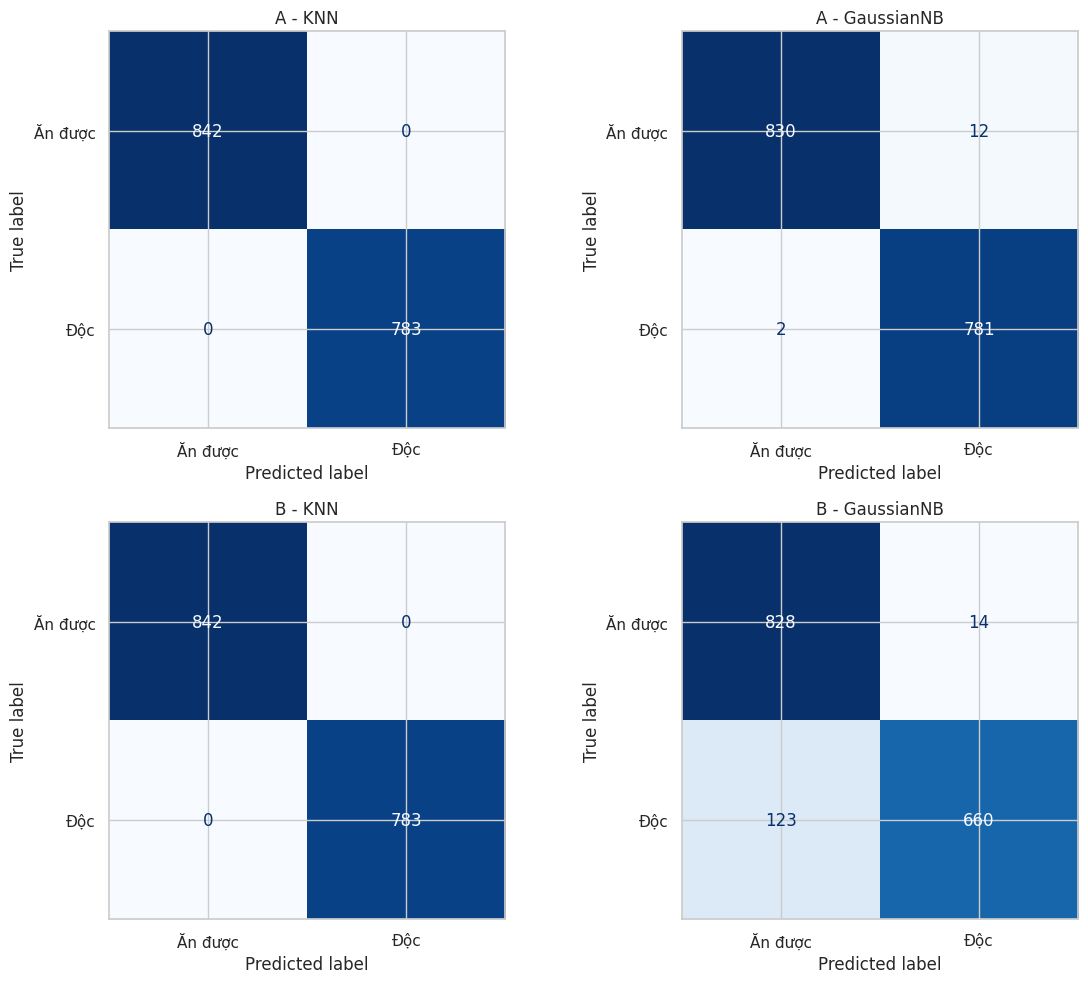

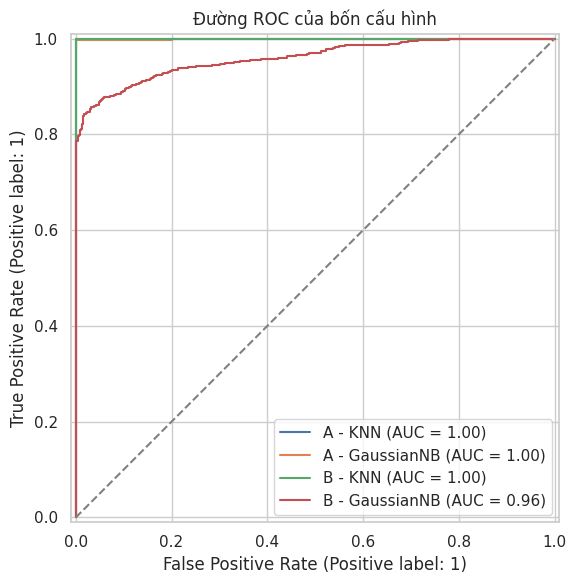

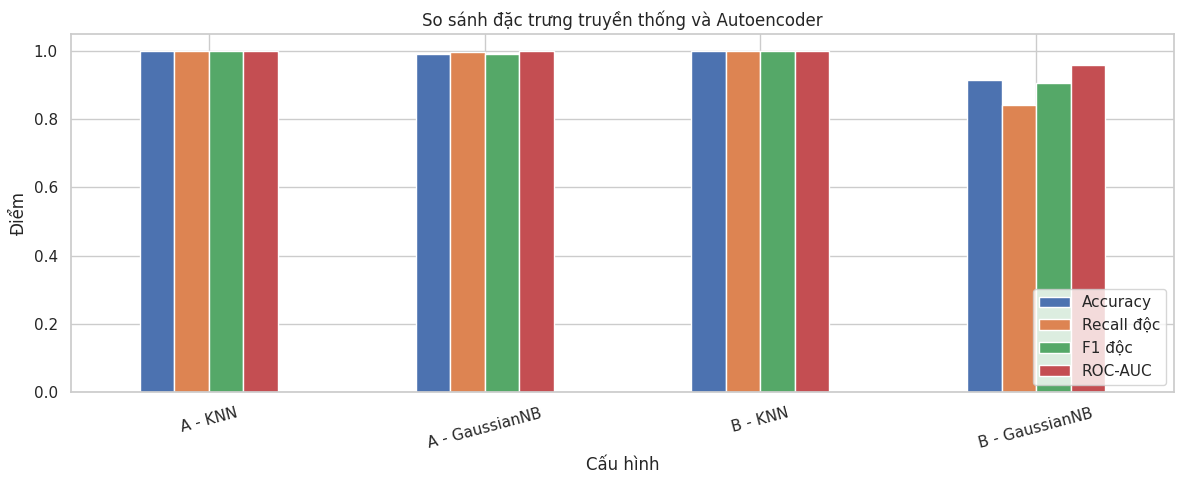

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, pred) in zip(
    axes.ravel(),
    test_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=[0, 1],
        display_labels=["Ăn được", "Độc"],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

for name, proba in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test,
        proba,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("Đường ROC của bốn cấu hình")
plt.tight_layout()
plt.show()

plot_data = results.copy()
plot_data["Cấu hình"] = (
    plot_data["Luồng"] + " - " + plot_data["Thuật toán"]
)

plot_data.set_index("Cấu hình")[
    ["Accuracy", "Recall độc", "F1 độc", "ROC-AUC"]
].plot.bar(figsize=(12, 5), rot=15)

plt.title("So sánh đặc trưng truyền thống và Autoencoder")
plt.ylabel("Điểm")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

11. Minh họa KNN để giải thích khi bảo vệ

In [12]:
knn_A = selected_models[("A", "KNN")]["model"]

sample_index = 0
sample = A_test[sample_index:sample_index + 1]

distances, indices = knn_A.kneighbors(sample)

neighbor_labels = y_train.iloc[
    indices[0]
].to_numpy()

bang_hang_xom = pd.DataFrame({
    "Thứ tự gần nhất": np.arange(1, len(indices[0]) + 1),
    "Khoảng cách": distances[0],
    "Nhãn": np.where(
        neighbor_labels == 1,
        "Độc",
        "Ăn được"
    )
})

display(bang_hang_xom)

print(
    "Nhãn thực tế:",
    "Độc" if y_test.iloc[sample_index] == 1 else "Ăn được"
)

print(
    "KNN dự đoán:",
    "Độc" if knn_A.predict(sample)[0] == 1 else "Ăn được"
)

,Thứ tự gần nhất,Khoảng cách,Nhãn
0,1,2.0,Độc
1,2,2.0,Độc
2,3,2.0,Độc


Nhãn thực tế: Độc
KNN dự đoán: Độc


12. Minh họa kết quả xác thực của Naive Bayes

In [13]:
nb_A = selected_models[("A", "GaussianNB")]["model"]

sample_index = 0
sample = A_test[sample_index:sample_index + 1]

prior = pd.DataFrame({
    "Lớp": [
        "Độc" if c == 1 else "Ăn được"
        for c in nb_A.classes_
    ],
    "Xác suất tiên nghiệm": nb_A.class_prior_
})

posterior = pd.DataFrame({
    "Lớp": [
        "Độc" if c == 1 else "Ăn được"
        for c in nb_A.classes_
    ],
    "Xác suất sau khi quan sát đặc trưng":
        nb_A.predict_proba(sample)[0]
})

display(prior)
display(posterior)

,Lớp,Xác suất tiên nghiệm
0,Ăn được,0.51785
1,Độc,0.48215


,Lớp,Xác suất sau khi quan sát đặc trưng
0,Ăn được,0.0
1,Độc,1.0


13. Lưu cấu hình

In [14]:
import os
import json
import shutil
import joblib
import sklearn

# Tạo thư mục chứa mô hình và kết quả
thu_muc = "mo_hinh_nam"
os.makedirs(thu_muc, exist_ok=True)

# 1. Lưu bộ tiền xử lý
joblib.dump(
    {
        "cot_giu": cot_giu,
        "imputer": imputer,
        "onehot": ohe
    },
    f"{thu_muc}/tien_xu_ly.pkl"
)

# 2. Lưu bốn bộ phân loại
for (luong, thuat_toan), record in selected_models.items():
    ten = f"{luong}_{thuat_toan}"

    joblib.dump(
        record["model"],
        f"{thu_muc}/{ten}.pkl"
    )

# 3. Lưu Encoder và Autoencoder
best_encoder.save(f"{thu_muc}/encoder.keras")
best_ae.save(f"{thu_muc}/autoencoder.keras")

# 4. Lưu các bảng kết quả
results.to_csv(
    f"{thu_muc}/ket_qua_test.csv",
    index=False,
    encoding="utf-8-sig"
)

validation_table.to_csv(
    f"{thu_muc}/ket_qua_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

ae_table.to_csv(
    f"{thu_muc}/ket_qua_autoencoder.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. Lưu thông tin để ứng dụng dùng lại
thong_tin = {
    "seed": SEED,
    "so_chieu_onehot": int(A_train.shape[1]),
    "so_chieu_an": int(best_z),
    "nhan": {"0": "Ăn được", "1": "Độc"},
    "tensorflow": tf.__version__,
    "scikit_learn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "gia_tri_nhap": {
        cot: sorted(
            X_train[cot].dropna().astype(str).unique().tolist()
        )
        for cot in cot_giu
    }
}

with open(
    f"{thu_muc}/thong_tin.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(thong_tin, f, ensure_ascii=False, indent=2)

print("Đã lưu:")
for ten_file in sorted(os.listdir(thu_muc)):
    print(" -", ten_file)

Đã lưu:
 - A_GaussianNB.pkl
 - A_KNN.pkl
 - B_GaussianNB.pkl
 - B_KNN.pkl
 - autoencoder.keras
 - encoder.keras
 - ket_qua_autoencoder.csv
 - ket_qua_test.csv
 - ket_qua_validation.csv
 - thong_tin.json
 - tien_xu_ly.pkl


14. kiểm tra lại mô hình có nạp lại hay không

In [15]:
# Nạp lại bộ tiền xử lý và Encoder
bo_xu_ly = joblib.load(f"{thu_muc}/tien_xu_ly.pkl")
encoder_da_luu = tf.keras.models.load_model(
    f"{thu_muc}/encoder.keras",
    compile=False
)

# Kiểm tra trên 10 mẫu test
mau = X_test.head(10)[bo_xu_ly["cot_giu"]]

mau_A = bo_xu_ly["onehot"].transform(
    bo_xu_ly["imputer"].transform(mau)
)

mau_B = encoder_da_luu.predict(mau_A, verbose=0)

for (luong, thuat_toan), record in selected_models.items():
    model_da_luu = joblib.load(
        f"{thu_muc}/{luong}_{thuat_toan}.pkl"
    )

    dau_vao = mau_A if luong == "A" else mau_B
    dau_vao_cu = feature_sets[luong][2][:10]

    du_doan_moi = model_da_luu.predict(dau_vao)
    du_doan_cu = record["model"].predict(dau_vao_cu)

    np.testing.assert_array_equal(du_doan_moi, du_doan_cu)
    print(f"{luong} - {thuat_toan}: Nạp lại thành công")

# Chỉ đóng gói sau khi kiểm tra thành công
shutil.make_archive(thu_muc, "zip", thu_muc)
files.download(f"{thu_muc}.zip")

A - KNN: Nạp lại thành công
A - GaussianNB: Nạp lại thành công
B - KNN: Nạp lại thành công
B - GaussianNB: Nạp lại thành công


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

15. GUI demo

In [16]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import output

output.enable_custom_widget_manager()

# Nạp dữ liệu cấu hình và các mô hình đã lưu
with open(
    f"{thu_muc}/thong_tin.json",
    encoding="utf-8"
) as f:
    cau_hinh = json.load(f)

bo_xu_ly_gui = joblib.load(
    f"{thu_muc}/tien_xu_ly.pkl"
)

encoder_gui = tf.keras.models.load_model(
    f"{thu_muc}/encoder.keras",
    compile=False
)

models_gui = {
    f"{luong} - {ten}": joblib.load(
        f"{thu_muc}/{luong}_{ten}.pkl"
    )
    for luong in ["A", "B"]
    for ten in ["KNN", "GaussianNB"]
}

# Tên thuộc tính bằng tiếng Việt
ten_cot = {
    "cap-shape": "Hình dạng mũ",
    "cap-surface": "Bề mặt mũ",
    "cap-color": "Màu mũ",
    "bruises": "Có vết bầm",
    "odor": "Mùi",
    "gill-attachment": "Kiểu gắn phiến",
    "gill-spacing": "Khoảng cách phiến",
    "gill-size": "Kích thước phiến",
    "gill-color": "Màu phiến",
    "stalk-shape": "Hình dạng cuống",
    "stalk-root": "Gốc cuống",
    "stalk-surface-above-ring": "Bề mặt trên vòng",
    "stalk-surface-below-ring": "Bề mặt dưới vòng",
    "stalk-color-above-ring": "Màu trên vòng",
    "stalk-color-below-ring": "Màu dưới vòng",
    "veil-color": "Màu màng",
    "ring-number": "Số vòng",
    "ring-type": "Loại vòng",
    "spore-print-color": "Màu bào tử",
    "population": "Kiểu quần thể",
    "habitat": "Môi trường sống"
}

# Một số giá trị phổ biến được hiển thị bằng tiếng Việt.
# Các giá trị khác vẫn giữ nguyên mã trong dữ liệu.
mau_sac = {
    "n": "Nâu", "b": "Vàng da bò", "c": "Quế",
    "g": "Xám", "r": "Xanh lá", "p": "Hồng",
    "u": "Tím", "e": "Đỏ", "w": "Trắng",
    "y": "Vàng", "k": "Đen", "o": "Cam"
}

dien_giai = {
    "cap-shape": {
        "b": "Hình chuông", "c": "Hình nón",
        "x": "Lồi", "f": "Phẳng",
        "k": "Có núm", "s": "Lõm"
    },
    "cap-surface": {
        "f": "Dạng sợi", "g": "Có rãnh",
        "y": "Có vảy", "s": "Nhẵn"
    },
    "bruises": {"t": "Có", "f": "Không"},
    "odor": {
        "a": "Hạnh nhân", "l": "Hồi",
        "c": "Creosote", "y": "Tanh",
        "f": "Hôi", "m": "Mốc", "n": "Không mùi",
        "p": "Hăng", "s": "Cay"
    },
    "gill-size": {"b": "Rộng", "n": "Hẹp"},
    "ring-number": {
        "n": "Không có", "o": "Một", "t": "Hai"
    },
    "habitat": {
        "g": "Đồng cỏ", "l": "Lá cây",
        "m": "Đồng cỏ tự nhiên", "p": "Đường đi",
        "u": "Đô thị", "w": "Nơi phế thải",
        "d": "Rừng"
    }
}

for cot in [
    "cap-color", "gill-color", "stalk-color-above-ring",
    "stalk-color-below-ring", "veil-color", "spore-print-color"
]:
    dien_giai[cot] = mau_sac

# Tạo các ô chọn
o_nhap = {}

for cot in bo_xu_ly_gui["cot_giu"]:
    values = cau_hinh["gia_tri_nhap"][cot]

    options = [
        (
            f"{dien_giai.get(cot, {}).get(v, v)} ({v})",
            v
        )
        for v in values
    ]

    if cot == "stalk-root":
        options.append(("Không rõ — dùng giá trị thay thế", "?"))

    o_nhap[cot] = widgets.Dropdown(
        options=options,
        description=ten_cot.get(cot, cot),
        style={"description_width": "155px"},
        layout=widgets.Layout(width="390px")
    )

chon_model = widgets.Dropdown(
    options=list(models_gui),
    description="Mô hình",
    style={"description_width": "155px"},
    layout=widgets.Layout(width="390px")
)

nut_du_doan = widgets.Button(
    description="Dự đoán",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="160px")
)

nut_mau = widgets.Button(
    description="Nạp mẫu minh họa",
    button_style="info",
    icon="refresh",
    layout=widgets.Layout(width="200px")
)

thong_bao_mau = widgets.HTML()
ket_qua_gui = widgets.Output()

# Dữ liệu minh họa lấy từ tập test
# Nhãn chỉ dùng để đối chiếu, không đưa vào mô hình.
trang_thai = {"index": -1}

def nap_mau(_):
    trang_thai["index"] = (
        trang_thai["index"] + 1
    ) % len(X_test)

    i = trang_thai["index"]
    sample = X_test.iloc[i]

    for cot, dropdown in o_nhap.items():
        value = sample[cot]
        value = "?" if pd.isna(value) else str(value)

        gia_tri_hop_le = [
            v for _, v in dropdown.options
        ]

        if value in gia_tri_hop_le:
            dropdown.value = value
        else:
            dropdown.value = gia_tri_hop_le[0]

    label = "Độc" if y_test.iloc[i] == 1 else "Ăn được"

    thong_bao_mau.value = (
        f"<p>Đã nạp mẫu test số <b>{i + 1}</b>. "
        f"Nhãn thực tế để đối chiếu: <b>{label}</b>. "
        "Nếu sửa các thuộc tính, nhãn này không còn "
        "áp dụng cho đầu vào đã sửa.</p>"
    )

    with ket_qua_gui:
        clear_output()

def du_doan(_):
    with ket_qua_gui:
        clear_output()

        try:
            row = pd.DataFrame([{
                cot: np.nan if dropdown.value == "?"
                else dropdown.value
                for cot, dropdown in o_nhap.items()
            }])

            row = row[bo_xu_ly_gui["cot_giu"]]

            features_A = bo_xu_ly_gui["onehot"].transform(
                bo_xu_ly_gui["imputer"].transform(row)
            )

            features_B = encoder_gui.predict(
                features_A, verbose=0
            )

            bang = []

            for name, model in models_gui.items():
                features = (
                    features_A
                    if name.startswith("A")
                    else features_B
                )

                pred = int(model.predict(features)[0])
                pos = list(model.classes_).index(1)
                probability = float(
                    model.predict_proba(features)[0, pos]
                )

                bang.append({
                    "Mô hình": name,
                    "Dự đoán": "Độc" if pred == 1 else "Ăn được",
                    "Xác suất lớp độc": probability
                })

            bang = pd.DataFrame(bang)

            selected = bang.loc[
                bang["Mô hình"] == chon_model.value
            ].iloc[0]

            color = (
                "#b91c1c"
                if selected["Dự đoán"] == "Độc"
                else "#166534"
            )

            display(widgets.HTML(
                f"""
                <div style="padding:18px;background:#f1f5f9;
                            border-radius:12px;margin:12px 0;">
                    <div>Mô hình: <b>{chon_model.value}</b></div>
                    <h2 style="color:{color};margin:8px 0;">
                        Dự đoán: {selected['Dự đoán']}
                    </h2>
                    <div>
                        Xác suất lớp độc theo mô hình:
                        <b>{selected['Xác suất lớp độc']:.2%}</b>
                    </div>
                </div>
                """
            ))

            print("Đối chiếu kết quả của cả bốn cấu hình:")
            display(
                bang.style.format({
                    "Xác suất lớp độc": "{:.2%}"
                })
            )

        except Exception as e:
            print("Không thể dự đoán:", str(e))

nut_mau.on_click(nap_mau)
nut_du_doan.on_click(du_doan)

tieu_de = widgets.HTML("""
<div style="padding:20px;background:#143d32;
            color:white;border-radius:12px;margin-bottom:16px;">
    <h2 style="margin:0;">PHÂN LOẠI NẤM</h2>
    <p>So sánh đặc trưng truyền thống và Autoencoder</p>
</div>
<p>
    Luồng A: One-Hot Encoding.
    Luồng B: đặc trưng học bằng Autoencoder.
</p>
<p>
    <b>Demo học tập:</b> kết quả không dùng để quyết định
    ăn nấm ngoài thực tế.
</p>
""")

luoi = widgets.GridBox(
    children=list(o_nhap.values()),
    layout=widgets.Layout(
        grid_template_columns="repeat(auto-fit, minmax(390px, 1fr))",
        grid_gap="8px",
        width="100%"
    )
)

display(widgets.VBox([
    tieu_de,
    chon_model,
    widgets.HTML("<h3>Đặc điểm đầu vào</h3>"),
    luoi,
    widgets.HTML("<br>"),
    widgets.HBox([nut_mau, nut_du_doan]),
    thong_bao_mau,
    ket_qua_gui
]))

# Nạp sẵn một mẫu để thử
nap_mau(None)

16. cập nhập

In [17]:
# Bổ sung tên tiếng Việt cho các mục còn thiếu
dien_giai.update({
    "gill-attachment": {
        "a": "Phiến gắn liền với cuống",
        "d": "Phiến chạy xuống cuống",
        "f": "Phiến rời cuống",
        "n": "Phiến có khía"
    },

    "gill-spacing": {
        "c": "Phiến mọc sát nhau",
        "w": "Phiến cách xa nhau",
        "d": "Phiến rất dày"
    },

    "stalk-shape": {
        "e": "Cuống to dần về phía gốc",
        "t": "Cuống thuôn nhỏ về phía gốc"
    },

    "stalk-root": {
        "b": "Gốc phình dạng củ",
        "c": "Gốc dạng chùy",
        "u": "Gốc dạng chén",
        "e": "Gốc có bề rộng đều",
        "z": "Gốc có sợi nấm bám",
        "r": "Gốc kéo dài dạng rễ"
    },

    "stalk-surface-above-ring": {
        "f": "Dạng sợi",
        "y": "Có vảy",
        "k": "Mượt như lụa",
        "s": "Nhẵn"
    },

    "stalk-surface-below-ring": {
        "f": "Dạng sợi",
        "y": "Có vảy",
        "k": "Mượt như lụa",
        "s": "Nhẵn"
    },

    "ring-type": {
        "c": "Dạng mạng nhện",
        "e": "Vòng sớm biến mất",
        "f": "Vòng loe rộng",
        "l": "Vòng lớn",
        "n": "Không có vòng",
        "p": "Vòng dạng váy",
        "s": "Vòng dạng màng mỏng",
        "z": "Vòng dạng đai"
    },

    "population": {
        "a": "Mọc nhiều",
        "c": "Mọc thành cụm",
        "n": "Mọc với số lượng lớn",
        "s": "Mọc rải rác",
        "v": "Mọc vài cây",
        "y": "Mọc đơn lẻ"
    }
})

# Cập nhật nhãn hiển thị, giữ nguyên mã đưa vào mô hình
for cot, dropdown in o_nhap.items():
    gia_tri_cu = dropdown.value
    options_moi = []

    for v in cau_hinh["gia_tri_nhap"][cot]:
        ten = dien_giai.get(cot, {}).get(v, v)
        options_moi.append((f"{ten} ({v})", v))

    if cot == "stalk-root":
        options_moi.append((
            "Không rõ — dùng giá trị thay thế",
            "?"
        ))

    dropdown.options = options_moi

    if gia_tri_cu in [v for _, v in options_moi]:
        dropdown.value = gia_tri_cu

print("Đã cập nhật tên tiếng Việt. Kéo lên giao diện để xem.")

Đã cập nhật tên tiếng Việt. Kéo lên giao diện để xem.
